# Covariance forecasts in portfolio decisions

Compare 26 allocation arms at 0, 5, 10 and 25 basis points per traded side. Each ETF path covers the same 1,975 development sessions. This notebook uses saved, audited ledgers; it does not fit a model or rerun a strategy. All 104 stock paths remain unsupported and have no full-period performance score.

In [1]:
from pathlib import Path
import hashlib, json, math
from statistics import mean, stdev
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').exists())
report=root/'reports/risk_economic_development_v1'
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
manifest=json.loads((report/'export-manifest.json').read_text())
assert (report/'COMPLETE').read_text().strip()==sha(report/'export-manifest.json')
assert manifest['complete'] and not manifest['scientific_family_complete']
assert not manifest['holdout_evaluated']
for name,digest in manifest['outputs_sha256'].items():
    assert sha(report/name)==digest
metrics=pd.read_csv(report/'path-metrics.csv',float_precision='round_trip')
daily=pd.read_parquet(report/'daily-paths.parquet')
support=pd.DataFrame(json.loads((report/'stock-support.json').read_text()))
assert len(metrics)==104 and len(daily)==205400 and len(support)==104
assert not daily.duplicated(['path_id','session']).any()
assert metrics.groupby('fee_bps').size().to_dict()=={0:26,5:26,10:26,25:26}
assert daily.groupby('path_id').size().eq(1975).all()
display(pd.DataFrame({'panel':['ETF8','stock100'],'complete_paths':[104,0], 'unsupported_paths':[0,104]}))
display(support.groupby(['failure_session','reason']).size().rename('paths').to_frame())

,panel,complete_paths,unsupported_paths
0,ETF8,104,0
1,stock100,0,104


,,paths
failure_session,reason,
2010-11-19,UNRESOLVED_SOURCE_MARK,104


## Recalculate the reported metrics

Recompute returns, annualized volatility, zero-cash-reference Sharpe, close-to-close drawdown, fees and turnover from every saved ETF path. The separate full accounting audit also reconciles trades, holdings and saved asset-PnL components. This is conditional on the source vintage and modeled execution assumptions; it does not independently reconstruct every original price mark.

In [2]:
replayed=[]
for path_id,frame in daily.groupby('path_id',sort=True):
    frame=frame.sort_values('session')
    nav=frame.close_nav.to_numpy()
    assert np.isfinite(nav).all() and (nav>0).all()
    returns=[float(current/previous-1) for current,previous in zip(nav,np.r_[100000.,nav[:-1]])]
    volatility=stdev(returns)*math.sqrt(252)
    peak=np.maximum.accumulate(np.r_[100000.,nav])[1:]
    calculated={'net_return':float(nav[-1]/100000-1),
      'annual_return_252_session_convention':float((nav[-1]/100000)**(252/1975)-1),
      'annual_volatility_sample_ddof1':volatility,
      'annual_sharpe_zero_cash_reference':mean(returns)*252/volatility,
      'maximum_close_nav_drawdown':float(np.min(nav/peak-1)),
      'total_fee_money':math.fsum(frame.fee),
      'total_full_buy_plus_sell_turnover':math.fsum(frame.full_turnover)}
    saved=metrics.set_index('path_id').loc[path_id]
    for name,value in calculated.items():
        assert math.isclose(value,float(saved[name]),rel_tol=1e-12,abs_tol=1e-12),(path_id,name)
    replayed.append({'path_id':path_id,**calculated})
assert len(replayed)==104
display(metrics[['fee_bps','arm','annual_return_252_session_convention',
 'annual_volatility_sample_ddof1','annual_sharpe_zero_cash_reference',
 'maximum_close_nav_drawdown','total_full_buy_plus_sell_turnover']].sort_values(['arm','fee_bps']))

,fee_bps,arm,annual_return_252_session_convention,annual_volatility_sample_ddof1,annual_sharpe_zero_cash_reference,maximum_close_nav_drawdown,total_full_buy_plus_sell_turnover
0,0,capped_inverse_volatility,0.059728,0.107261,0.594505,-0.292152,8.428821
78,5,capped_inverse_volatility,0.059159,0.107261,0.589491,-0.292380,8.428045
26,10,capped_inverse_volatility,0.058589,0.107262,0.584476,-0.292608,8.427281
52,25,capped_inverse_volatility,0.056884,0.107266,0.569419,-0.293290,8.424996
1,0,constant_correlation_fixed0p5_eta0,0.066869,0.077611,0.872925,-0.209765,17.872742
...,...,...,...,...,...,...,...
76,25,sample_ddof1_eta0p01,0.073394,0.076300,0.966503,-0.183183,15.153471
25,0,sample_ddof1_eta0p1,0.074635,0.076909,0.974491,-0.192637,4.876047
103,5,sample_ddof1_eta0p1,0.074300,0.076908,0.970448,-0.192815,4.875377
51,10,sample_ddof1_eta0p1,0.073966,0.076909,0.966399,-0.192992,4.874724


## Fees and allocation stability

Read each row across fee scenarios. The covariance estimator and turnover penalty identify an arm; all arms are retained, without selecting a winner from this display. Sharpe ratios here are descriptive development estimates, not independent confirmation of an investment edge.

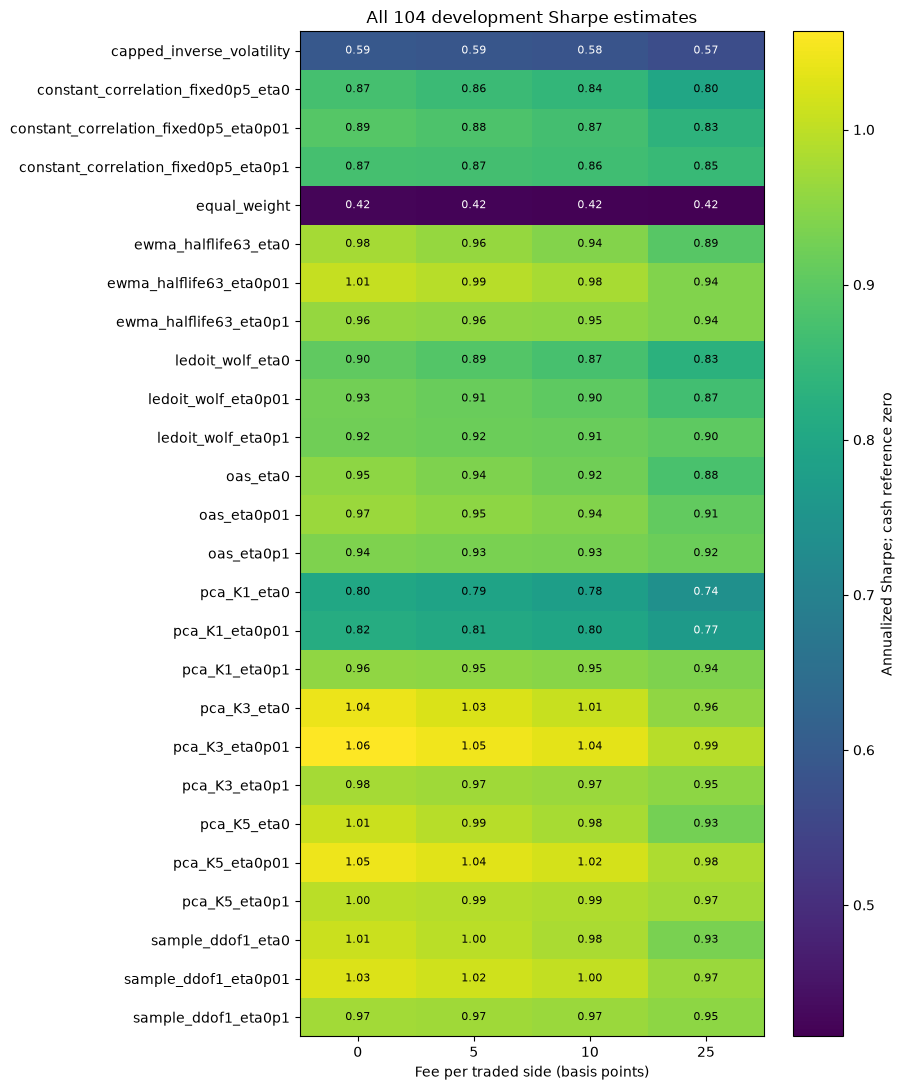

In [3]:
arms=sorted(metrics.arm.unique())
wide=metrics.pivot(index='arm',columns='fee_bps',values='annual_sharpe_zero_cash_reference').reindex(arms)
fig,ax=plt.subplots(figsize=(9,11))
im=ax.imshow(wide.to_numpy(),aspect='auto',cmap='viridis')
ax.set_yticks(range(len(arms)),arms)
ax.set_xticks(range(4),[str(x) for x in wide.columns])
ax.set(xlabel='Fee per traded side (basis points)',title='All 104 development Sharpe estimates')
for i in range(len(arms)):
    for j in range(4):ax.text(j,i,f'{wide.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8,color='black' if im.norm(wide.iloc[i,j])>.55 else 'white')
fig.colorbar(im,ax=ax,label='Annualized Sharpe; cash reference zero')
fig.tight_layout();plt.show()

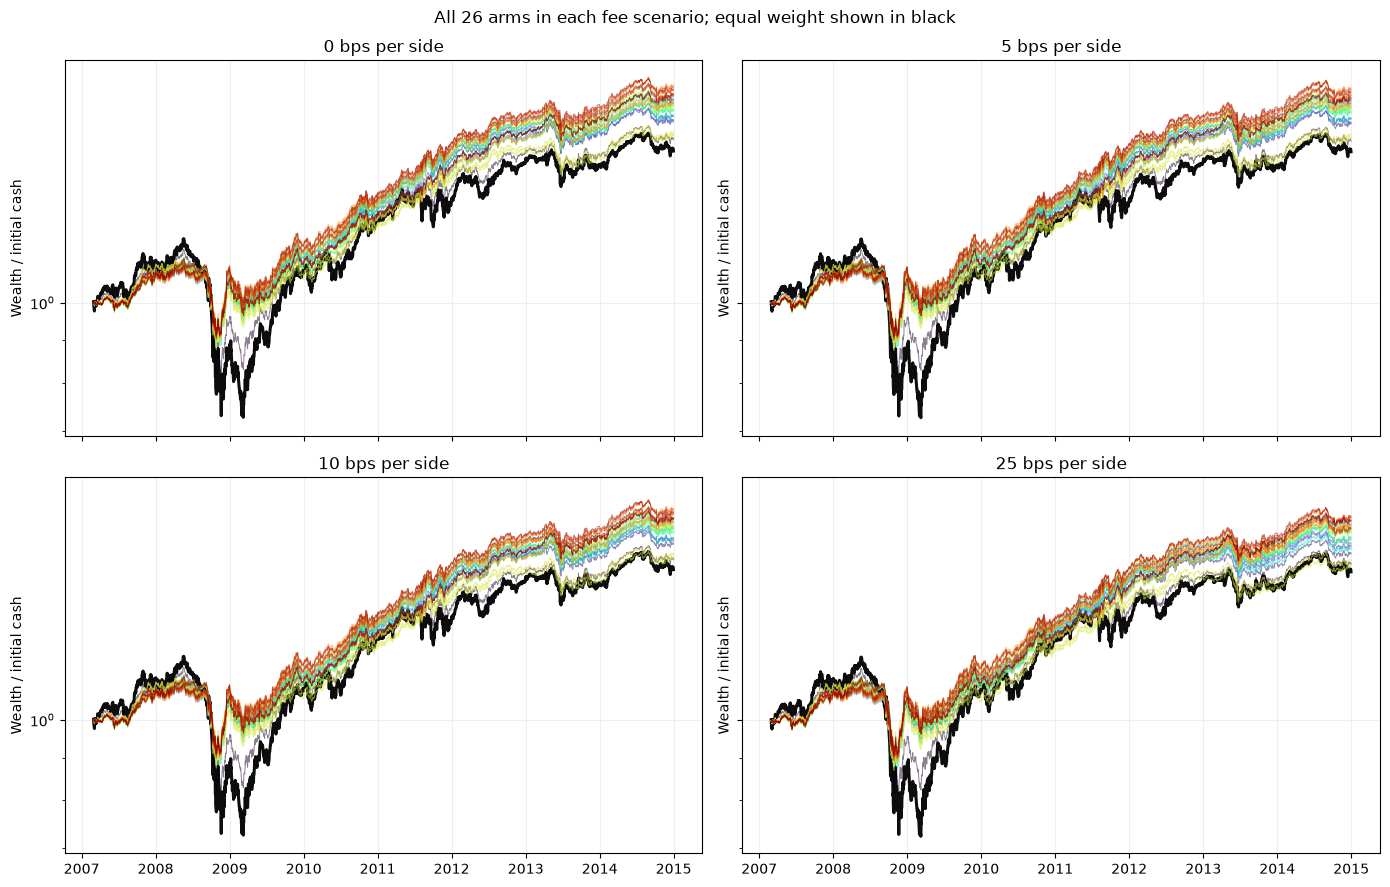

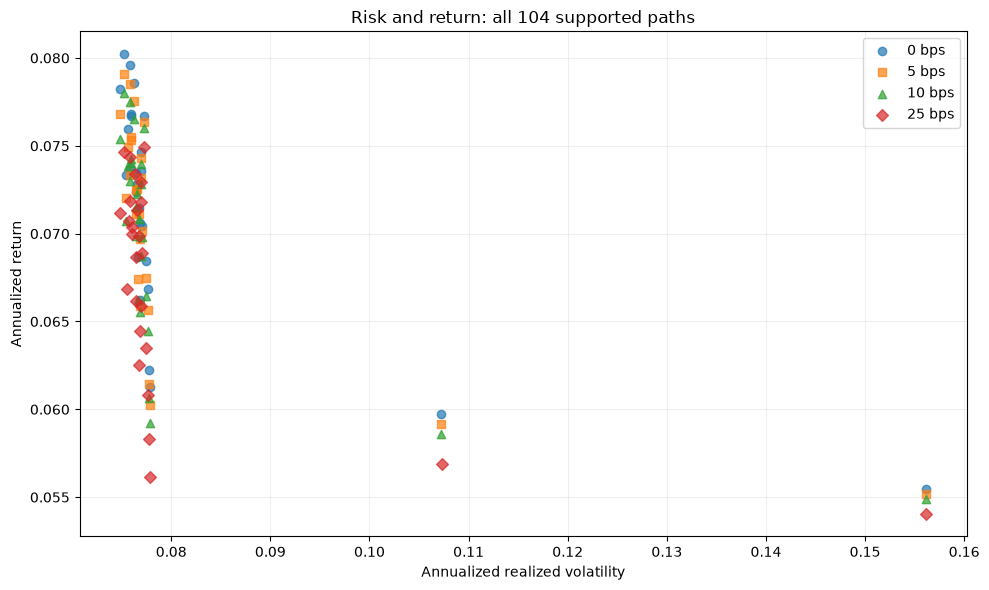

In [4]:
colors={arm:plt.get_cmap('turbo')(i/(len(arms)-1)) for i,arm in enumerate(arms)}
fig,axes=plt.subplots(2,2,figsize=(14,9),sharex=True,sharey=True)
for fee,ax in zip([0,5,10,25],axes.flat):
    for arm in arms:
        frame=daily[daily.path_id.eq(f'etf8/cost{fee}/{arm}')].sort_values('session')
        ax.plot(pd.to_datetime(frame.session),frame.close_nav/100000,
          color='black' if arm=='equal_weight' else colors[arm],
          linewidth=2.2 if arm=='equal_weight' else .7,alpha=.95 if arm=='equal_weight' else .55)
    ax.set(title=f'{fee} bps per side',ylabel='Wealth / initial cash',yscale='log')
    ax.grid(alpha=.2)
fig.suptitle('All 26 arms in each fee scenario; equal weight shown in black')
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(10,6))
for fee,marker in zip([0,5,10,25],['o','s','^','D']):
    subset=metrics[metrics.fee_bps.eq(fee)]
    ax.scatter(subset.annual_volatility_sample_ddof1,
      subset.annual_return_252_session_convention,label=f'{fee} bps',marker=marker,alpha=.7)
ax.set(xlabel='Annualized realized volatility',ylabel='Annualized return',title='Risk and return: all 104 supported paths')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();plt.show()

## Scope of the result

All ETF paths have full development support. Stock portfolios stop when an owned asset lacks its required opening mark; no prices or exits are invented, and partial prefixes are not scored as full-period results. The broader 208-path family therefore remains incomplete. These plots do not replace paired uncertainty, final recipe selection, or the untouched shared final-period evaluation.